KUMARA P.K.M.P. : 230353N 

##### 1. Blob detection

Number of detected blobs: 53
Center=(0, 275), radius=10, sigma=7.2, response=1.3794
Center=(282, 338), radius=10, sigma=7.2, response=1.3962
Center=(223, 174), radius=9, sigma=6.2, response=1.0061
Center=(179, 327), radius=9, sigma=6.2, response=1.3683
Center=(53, 174), radius=8, sigma=5.7, response=1.2012
Center=(106, 255), radius=8, sigma=5.7, response=1.4422
Center=(178, 261), radius=8, sigma=5.7, response=1.3992
Center=(187, 174), radius=7, sigma=4.7, response=1.0414
Center=(189, 240), radius=7, sigma=4.7, response=1.4294
Center=(274, 258), radius=7, sigma=4.7, response=1.3682
Center=(63, 243), radius=6, sigma=4.2, response=1.4088
Center=(19, 250), radius=6, sigma=4.2, response=1.1515
Center=(70, 286), radius=6, sigma=4.2, response=1.3992
Center=(161, 290), radius=6, sigma=4.2, response=1.4441
Center=(121, 177), radius=5, sigma=3.2, response=1.2024
Center=(254, 219), radius=5, sigma=3.2, response=1.4145
Center=(119, 222), radius=5, sigma=3.2, response=1.5042
Center=(345, 229), radi

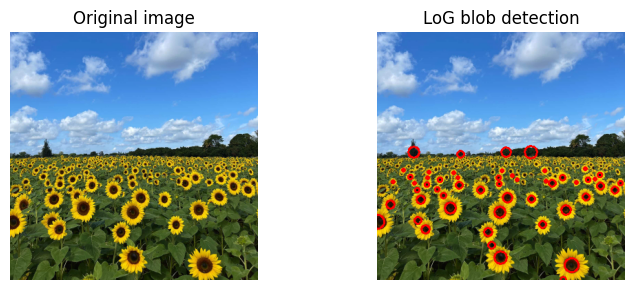

In [108]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter, minimum_filter

img_path = r'C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\the_berry_farms_sunflower_field.jpeg'
im = cv.imread(img_path, cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

sigmas = np.arange(1.2, 12.3, 0.5)
threshold = 1.0

responses = [] #to store scaled_normal LoG responses

for sigma in sigmas:          #Calculate LoG at each scale

    blurred = cv.GaussianBlur(                #Gaussian blur
        gray, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma)
    )
    lap = cv.Laplacian(blurred, cv.CV_32F, ksize=3) #Laplacian of blured image
    response = (sigma ** 2) * lap #scale normal LoG response
    responses.append(response)  #positive response for dark blobs

responses = np.stack(responses, axis=0)

kernel = np.ones((3, 3, 3), dtype=bool)

local_max = (
    responses == maximum_filter(responses, footprint=kernel)
)
candidates = local_max & (responses > threshold) #keep only strong responses

candidates[0, :, :] = False      #Discard first sigma value
candidates[-1, :, :] = False     #Discard last sigma value

scale_idx, ys, xs = np.where(candidates) #blob positions and scales

blobs = []
for s, y, x in zip(scale_idx, ys, xs):
    sigma = sigmas[s]
    strength = responses[s, y, x]
    radius = int(round(np.sqrt(2) * sigma))   #radius of gaussian shaped blob
    blobs.append((x, y, radius, strength, sigma))

result = im.copy() #draw detected circles

for x, y, radius, strength, sigma in blobs:
    cv.circle(result, (x, y), radius, (0, 0, 255), 2)
print("Number of detected blobs:", len(blobs))

for x, y, radius, strength, sigma in sorted(
    blobs, key=lambda b: b[2], reverse=True
)[:20]:
    print(
        f"Center=({x}, {y}), radius={radius}, "
        f"sigma={sigma:.1f}, response={strength:.4f}"
    )

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.title("Original image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("LoG blob detection")
plt.axis("off")
plt.tight_layout()
plt.show()

##### 2. RANSAC Model Fitting

In [109]:
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))
X = np.vstack((X_circ, X_line))  # All points

In [110]:
#Line model: a*x + b*y = d
def fit_line_two_points(p1, p2): #line through 2 points, unit normal (a,b), distance d
    direction = p2 - p1
    norm = np.linalg.norm(direction)
    if norm < 1e-12:
        return None
    direction = direction / norm
    a, b_ = -direction[1], direction[0]  # unit normal
    d = a * p1[0] + b_ * p1[1]    #distance
    return np.array([a, b_, d])

def fit_line_tls(P):  #TLS line fit with constaraint of unit normal (a,b)
    # normal = eigenvector of scatter matrix with smallest eigenvalue.
    mu = P.mean(axis=0)
    Pc = P - mu
    _, _, Vt = np.linalg.svd(Pc, full_matrices=False)
    a, b_ = Vt[-1]                      # unit norm
    d = a * mu[0] + b_ * mu[1]
    return np.array([a, b_, d])

def line_error(P, model):
    a, b_, d = model
    return np.abs(P @ np.array([a, b_]) - d)  # normal distance

def ransac_line(X, thresh, min_inliers, n_iter=1000):
    best_model, best_inliers, best_sample = None, np.array([], dtype=int), None
    for _ in range(n_iter):
        idx = np.random.choice(len(X), 2, replace=False)
        model = fit_line_two_points(X[idx[0]], X[idx[1]])
        if model is None:
            continue
        inliers = np.where(line_error(X, model) < thresh)[0]
        if len(inliers) >= min_inliers and len(inliers) > len(best_inliers):
            best_model, best_inliers, best_sample = model, inliers, idx
    return best_model, best_inliers, best_sample

line_thresh = 2.0
line_min_inliers = 40

line_sample_model, line_inliers, line_sample_idx = ransac_line(
    X, line_thresh, line_min_inliers, n_iter=1000
)
line_sample_pts = X[line_sample_idx]
line_best = fit_line_tls(X[line_inliers])     # refit on all inliers (TLS, ||n||=1)
print("Line (a, b, d) from best sample:", line_sample_model)
print("Line (a, b, d) refit on inliers :", line_best)
print("Norm of [a,b] =", np.linalg.norm(line_best[:2]))
print("# line inliers:", len(line_inliers))

Line (a, b, d) from best sample: [-0.73034331 -0.68308027 -1.04665129]
Line (a, b, d) refit on inliers : [0.71452919 0.69960563 1.25475323]
Norm of [a,b] = 1.0000000000000002
# line inliers: 61


In [111]:
#  Circle model: center (cx,cy), radius r 
def circle_from_three_points(p1, p2, p3):
    A = np.array([
        [p2[0] - p1[0], p2[1] - p1[1]],
        [p3[0] - p1[0], p3[1] - p1[1]],
    ])
    if abs(np.linalg.det(A)) < 1e-9:  # collinear
        return None
    rhs = 0.5 * np.array([
        p2 @ p2 - p1 @ p1,
        p3 @ p3 - p1 @ p1,
    ])
    c = np.linalg.solve(A, rhs)
    rad = np.linalg.norm(p1 - c)
    return np.array([c[0], c[1], rad])

def circle_error(P, model):
    cx, cy, rad = model
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rad)   # radial error

def fit_circle_opt(P, init):
    def cost(p):
        return np.sum((np.hypot(P[:, 0] - p[0], P[:, 1] - p[1]) - p[2]) ** 2)
    res = minimize(cost, init, method='BFGS')
    return res.x

def ransac_circle(X, thresh, min_inliers, n_iter=2000):
    best_model, best_inliers, best_sample = None, np.array([], dtype=int), None
    for _ in range(n_iter):
        idx = np.random.choice(len(X), 3, replace=False)
        model = circle_from_three_points(X[idx[0]], X[idx[1]], X[idx[2]])
        if model is None or model[2] > 50:    # reject absurdly large circles
            continue
        inliers = np.where(circle_error(X, model) < thresh)[0]
        if len(inliers) >= min_inliers and len(inliers) > len(best_inliers):
            best_model, best_inliers, best_sample = model, inliers, idx
    return best_model, best_inliers, best_sample

mask = np.ones(len(X), dtype=bool)
mask[line_inliers] = False
X_rem = X[mask]

circ_thresh = 1.25
circ_min_inliers = 35

circ_sample_model, circ_inliers, circ_sample_idx = ransac_circle(
    X_rem, circ_thresh, circ_min_inliers, n_iter=2000
)
circ_sample_pts = X_rem[circ_sample_idx]
circ_best = fit_circle_opt(X_rem[circ_inliers], circ_sample_model) 
print("Circle (cx, cy, r) from best sample:", circ_sample_model)
print("Circle (cx, cy, r) refit on inliers :", circ_best)
print("# circle inliers:", len(circ_inliers))

Circle (cx, cy, r) from best sample: [ 1.92711325  3.0303737  10.12155356]
Circle (cx, cy, r) refit on inliers : [1.97693799 3.00091541 9.91954227]
# circle inliers: 39


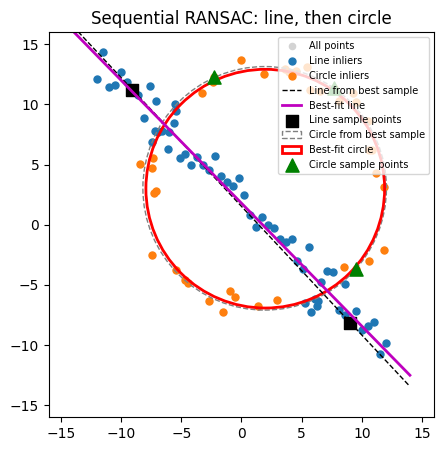

In [112]:
#plot
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

ax.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], c='tab:blue', s=25,
           label='Line inliers')
ax.scatter(X_rem[circ_inliers, 0], X_rem[circ_inliers, 1], c='tab:orange',
           s=25, label='Circle inliers')

xs = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 200)

def line_y(model, xs):
    a, b_, d = model
    return (d - a * xs) / b_

# line from the best sample (2 points)
ax.plot(xs, line_y(line_sample_model, xs), 'k--', lw=1,
        label='Line from best sample')
# best-fit line
ax.plot(xs, line_y(line_best, xs), 'm-', lw=2, label='Best-fit line')
# the 2 sample points for line
ax.scatter(line_sample_pts[:, 0], line_sample_pts[:, 1], c='k', marker='s',
           s=80, label='Line sample points')

# circle from the best sample (3 points)
ax.add_patch(plt.Circle(circ_sample_model[:2], circ_sample_model[2],
                        color='gray', fill=False, ls='--', lw=1,
                        label='Circle from best sample'))
# best-fit circle
ax.add_patch(plt.Circle(circ_best[:2], circ_best[2], color='r', fill=False,
                        lw=2, label='Best-fit circle'))
# the 3 sample points for circle
ax.scatter(circ_sample_pts[:, 0], circ_sample_pts[:, 1], c='g', marker='^',
           s=90, label='Circle sample points')

ax.set_aspect('equal')
ax.set_xlim(-16, 16)
ax.set_ylim(-16, 16)
ax.legend(loc='upper right', fontsize=7)
ax.set_title('Sequential RANSAC: line, then circle')
plt.show()

To generate circle need 3 points from circle and to generate line need 2 points from line. Probability of choosing 3 points from the circle is (0.5)^3 -> 12.5% 
Probability of choosing 3 points from the line is (0.5)^2 -> 25% 
So RANSAC need many iterations to select correct points to construct circle. 

Also circle with the very large radius, look like line in small region. So here circle with a very large radius can fit enough to line points and incorrectly generate circle. 


##### 3. Superimpose

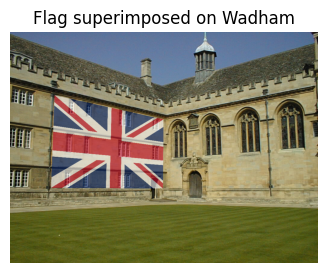

[[ 2.78681065e-01 -1.60497795e-02  1.48000000e+02]
 [ 9.29224031e-02  3.07312850e-01  2.10000000e+02]
 [ 1.76743919e-04 -2.61013199e-05  1.00000000e+00]]


In [113]:
import cv2, numpy as np

def superimpose(arch, flag, pts, alpha=0.6):
    h, w = flag.shape[:2]
    src = np.float32([[0,0],[w,0],[w,h],[0,h]])      # flag corners
    dst = np.float32(pts)                             # clicked points
    H = cv2.getPerspectiveTransform(src, dst)         # 4-point homography
    H_, W_ = arch.shape[:2]
    warped = cv2.warpPerspective(flag, H, (W_, H_))
    mask = cv2.warpPerspective(np.full((h,w),255,np.uint8), H, (W_,H_)) / 255.0
    m = (mask*alpha)[...,None]
    out = arch*(1-m) + warped*m
    return out.astype(np.uint8), H

arch = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\wadham.jpg")
union = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\flag.png")

p1 = [(148,210),(510,290),(508,520),(136,518)]   # TL, TR, BR, BL on the left wall
out1, H1 = superimpose(arch, union, p1, 0.6)

plt.figure(figsize=(6, 3))
plt.imshow(cv2.cvtColor(out1, cv2.COLOR_BGR2RGB))   # BGR -> RGB for matplotlib
plt.axis("off")
plt.title("Flag superimposed on Wadham")
plt.show()

print(H1)

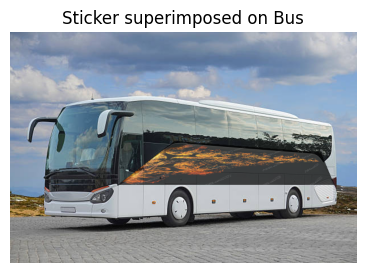

[[ 7.44942529e-01 -5.92113068e-01  2.90000000e+02]
 [ 1.55172414e-01 -5.53336084e-02  1.92000000e+02]
 [ 5.74712644e-04 -1.23668532e-03  1.00000000e+00]]


In [114]:
arch2 = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\bus.jpg")
union2 = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\sticker.png")

p2 = [(290,192),(548,212),(572,270),(190,270)]   # TL, TR, BR, BL on the left wall
out2, H2 = superimpose(arch2, union2, p2, 0.7)

plt.figure(figsize=(6, 3))
plt.imshow(cv2.cvtColor(out2, cv2.COLOR_BGR2RGB))   # BGR -> RGB for matplotlib
plt.axis("off")
plt.title("Sticker superimposed on Bus")
plt.show()

print(H2)

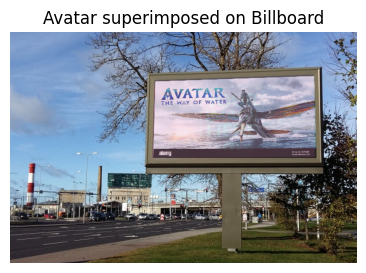

[[ 3.63491662e-01 -2.53029367e-02  2.72000000e+02]
 [-2.13435589e-02  3.24014995e-01  9.20000000e+01]
 [-9.04388091e-05 -5.93778556e-05  1.00000000e+00]]


In [115]:
arch3 = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\billboard.jpg")
union3 = cv2.imread(r"C:\Users\minsa\OneDrive\Desktop\Image Processing and Machine Vision\CV_assignment_02\avatar.jpeg")

p3 = [(272,92),(570,82),(574,236),(268,236)]   # TL, TR, BR, BL on the billboard
out3, H3 = superimpose(arch3, union3, p3, 0.7)

plt.figure(figsize=(6, 3))
plt.imshow(cv2.cvtColor(out3, cv2.COLOR_BGR2RGB))   # BGR -> RGB for matplotlib
plt.axis("off")
plt.title("Avatar superimposed on Billboard")
plt.show()

print(H3)

##### 4. PCB Image Alignment

Template keypoints: 14272
AAAA1.jpg: good matches=451, inliers=36


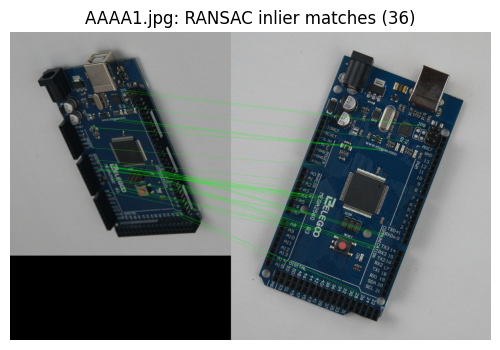

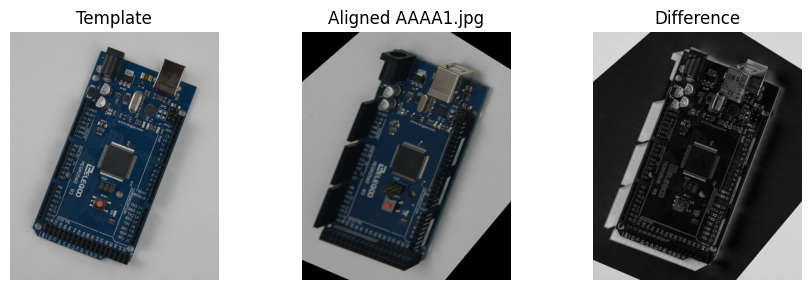

ADAD1.jpg: good matches=369, inliers=194


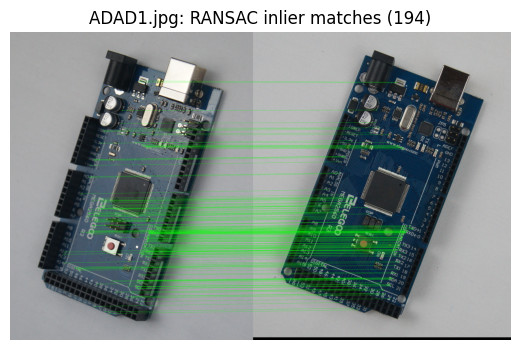

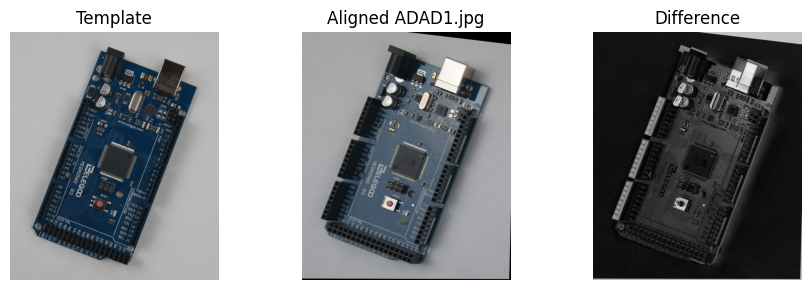

In [116]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

template = cv2.imread("AECC1.jpg")
t_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
h, w = template.shape[:2]

# Lowe ratio per image
images = {"AAAA1.jpg": 0.9, "ADAD1.jpg": 0.75}

#(a) SIFT on the template
sift = cv2.SIFT_create()
kp_t, des_t = sift.detectAndCompute(t_gray, None)
print("Template keypoints:", len(kp_t))

bf = cv2.BFMatcher()

for fname, ratio in images.items():
    img = cv2.imread(fname)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # (a) SIFT on the given image
    kp, des = sift.detectAndCompute(gray, None)

    # (b) Match features (query = given image, train = template) + ratio test
    knn = bf.knnMatch(des, des_t, k=2)
    good = [m for m, n in knn if m.distance < ratio * n.distance]

    src_pts = np.float32([kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    # Homography with RANSAC
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0,
                                 maxIters=10000, confidence=0.999)
    inliers = mask.ravel().astype(bool)
    print(f"{fname}: good matches={len(good)}, inliers={inliers.sum()}")

    # Draw the inlier matches across the two images
    inlier_matches = [m for m, keep in zip(good, inliers) if keep]
    match_img = cv2.drawMatches(
        img, kp, template, kp_t, inlier_matches, None,
        matchColor=(0, 255, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # (c) Warp the image onto the template and take the difference
    aligned = cv2.warpPerspective(img, H, (w, h))
    diff = cv2.absdiff(aligned, template)
    diff_gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)

    #results of inline
    plt.figure(figsize=(8, 4))
    plt.imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB))
    plt.title(f"{fname}: RANSAC inlier matches ({inliers.sum()})")
    plt.axis("off")
    plt.show()

    fig, ax = plt.subplots(1, 3, figsize=(9, 3))
    ax[0].imshow(cv2.cvtColor(template, cv2.COLOR_BGR2RGB)); ax[0].set_title("Template")
    ax[1].imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB));  ax[1].set_title("Aligned " + fname)
    ax[2].imshow(diff_gray, cmap="gray");                    ax[2].set_title("Difference")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()